In [1]:
lugares = {
    "UNSAAC": (-13.52174, -71.95870),
    "Cristo Blanco": (-13.50955, -71.97813),
    "Sacsayhuaman": (-13.50670, -71.98070),
    "Bombonera Alto Los Incas": (-13.51717, -71.95202)
}

# Mostrar los lugares y sus coordenadas
for nombre, (lat, lon) in lugares.items():
    print(f"{nombre}: lat={lat}, lon={lon}")

UNSAAC: lat=-13.52174, lon=-71.9587
Cristo Blanco: lat=-13.50955, lon=-71.97813
Sacsayhuaman: lat=-13.5067, lon=-71.9807
Bombonera Alto Los Incas: lat=-13.51717, lon=-71.95202


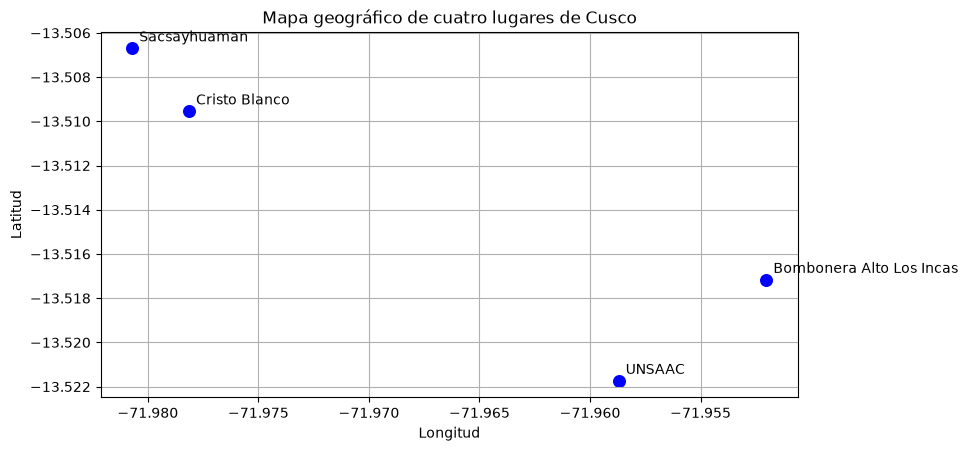

In [2]:
import matplotlib.pyplot as plt

# Extraer nombres y coordenadas
nombres = list(lugares.keys())

lats = [coord[0] for coord in lugares.values()]
lons = [coord[1] for coord in lugares.values()]

# Crear el gráfico
fig, ax = plt.subplots(figsize=(9, 7))

# Graficar los puntos
ax.scatter(lons, lats, color="blue", s=70)

# Agregar nombres
for nombre, lat, lon in zip(nombres, lats, lons):
    ax.annotate(nombre, (lon, lat),
                xytext=(5, 5),
                textcoords="offset points")

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Mapa geográfico de cuatro lugares de Cusco")

ax.set_aspect("equal")
ax.grid(True)

# Guardar el mapa
plt.savefig("mapa_basico.png", dpi=180)

plt.show()

In [5]:
import math

def distancia_haversine(lat1, lon1, lat2, lon2):

    R = 6371

    lat1 = math.radians(lat1)
    lat2 = math.radians(lat2)

    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)

    a = (math.sin(dlat / 2)**2 +
         math.cos(lat1) * math.cos(lat2) *
         math.sin(dlon / 2)**2)

    c = 2 * math.asin(math.sqrt(a))

    return R * c

In [6]:
primer_nombre = list(lugares.keys())[0]

primera_coord = lugares[primer_nombre]

print("Distancias desde:", primer_nombre)

for nombre, (lat, lon) in list(lugares.items())[1:]:

    distancia = distancia_haversine(
        primera_coord[0],
        primera_coord[1],
        lat,
        lon
    )

    print(f"Hasta {nombre}: {distancia:.3f} km")

Distancias desde: UNSAAC
Hasta Cristo Blanco: 2.101 km
Hasta Sacsayhuaman: 2.379 km
Hasta Bombonera Alto Los Incas: 0.722 km


In [7]:
from itertools import combinations

resultados = []

# Calcular todas las combinaciones
for (nombre1, coord1), (nombre2, coord2) in combinations(
    lugares.items(), 2
):

    distancia = distancia_haversine(
        coord1[0], coord1[1],
        coord2[0], coord2[1]
    )

    resultados.append((distancia, nombre1, nombre2))

# Encontrar el más cercano y el más lejano
par_cercano = min(resultados, key=lambda x: x[0])
par_lejano = max(resultados, key=lambda x: x[0])

print("PAR MÁS CERCANO:")
print(par_cercano[1], "-", par_cercano[2])
print("Distancia:", round(par_cercano[0], 3), "km")

print("\nPAR MÁS LEJANO:")
print(par_lejano[1], "-", par_lejano[2])
print("Distancia:", round(par_lejano[0], 3), "km")

PAR MÁS CERCANO:
Cristo Blanco - Sacsayhuaman
Distancia: 0.278 km

PAR MÁS LEJANO:
Sacsayhuaman - Bombonera Alto Los Incas
Distancia: 3.101 km


In [8]:
import json

# Crear una lista vacía
features = []

# Recorrer los cuatro lugares
for nombre, (lat, lon) in lugares.items():

    feature = {
        "type": "Feature",

        "properties": {
            "nombre": nombre
        },

        "geometry": {
            "type": "Point",
            "coordinates": [lon, lat]
        }
    }

    features.append(feature)

# Crear el GeoJSON completo
geojson_mio = {
    "type": "FeatureCollection",
    "features": features
}

# Guardar el archivo
with open("mis_lugares.geojson", "w", encoding="utf-8") as archivo:

    json.dump(
        geojson_mio,
        archivo,
        ensure_ascii=False,
        indent=2
    )

print("Archivo GeoJSON guardado correctamente")

Archivo GeoJSON guardado correctamente


In [9]:
# Abrir el archivo GeoJSON
with open("mis_lugares.geojson", "r", encoding="utf-8") as archivo:

    geojson_leido = json.load(archivo)

# Verificar la cantidad de lugares
print("Cantidad de lugares:",
      len(geojson_leido["features"]))

# Mostrar el primer lugar
primer_feature = geojson_leido["features"][0]

print("Primer lugar:",
      primer_feature["properties"]["nombre"])

print("Coordenadas:",
      primer_feature["geometry"]["coordinates"])

# Verificar los datos
assert len(geojson_leido["features"]) == 4

lon = list(lugares.values())[0][1]
lat = list(lugares.values())[0][0]

assert primer_feature["geometry"]["coordinates"] == [lon, lat]

print("Verificación correcta: los datos coinciden.")

Cantidad de lugares: 4
Primer lugar: UNSAAC
Coordenadas: [-71.9587, -13.52174]
Verificación correcta: los datos coinciden.
